In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("spam_ham_dataset.csv")

In [3]:
data.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


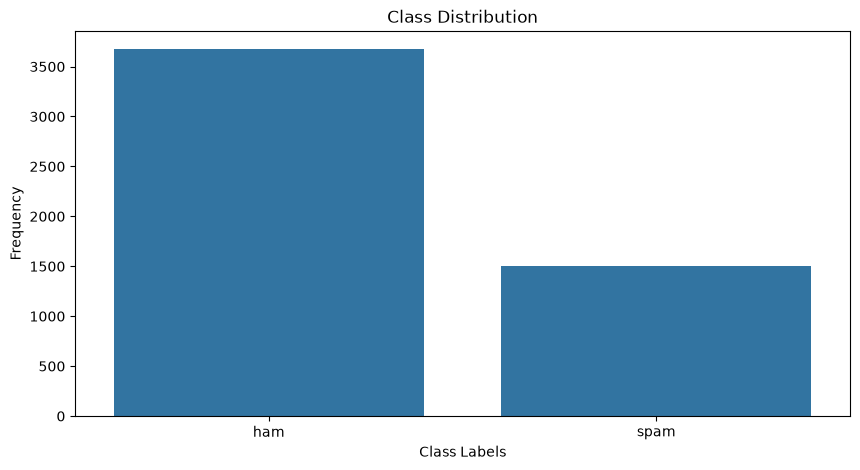

In [4]:
# Class Balance Analysis
class_counts = data['label'].value_counts()
# Plot the class distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title('Class Distribution')
plt.ylabel('Frequency')
plt.xlabel('Class Labels')
plt.show()

In [5]:
from collections import Counter

In [6]:
data[data['label'] == "ham"]['text']

0       Subject: enron methanol ; meter # : 988291\r\n...
1       Subject: hpl nom for january 9 , 2001\r\n( see...
2       Subject: neon retreat\r\nho ho ho , we ' re ar...
4       Subject: re : indian springs\r\nthis deal is t...
5       Subject: ehronline web address change\r\nthis ...
                              ...                        
5165    Subject: fw : crosstex energy , driscoll ranch...
5166    Subject: put the 10 on the ft\r\nthe transport...
5167    Subject: 3 / 4 / 2000 and following noms\r\nhp...
5168    Subject: calpine daily gas nomination\r\n>\r\n...
5169    Subject: industrial worksheets for august 2000...
Name: text, Length: 3672, dtype: str

In [7]:
def get_most_common_words(class_lebel, num_words, colume_name, dataset):
  text = " ".join(message for message in dataset[dataset['label'] == class_lebel][colume_name])
  word = text.lower().split()
  return Counter(word).most_common(num_words)

In [8]:
spam_words = get_most_common_words('spam', 20, "text", data)
ham_words = get_most_common_words('ham', 20, "text", data)

In [9]:
ham_words

[('-', 77782),
 ('/', 37141),
 ('.', 35192),
 (',', 29413),
 (':', 20492),
 ('the', 18359),
 ('to', 15172),
 ('ect', 13897),
 ('@', 12168),
 ('for', 7982),
 ('and', 7912),
 ('hou', 7281),
 ('enron', 6555),
 ('on', 6049),
 ('a', 6026),
 ("'", 5780),
 ('of', 5677),
 ('>', 5559),
 ('you', 5365),
 ('i', 5241)]

In [10]:
len("this is an spam email")

21

In [11]:
data['text_length'] = data['text'].apply(len)

In [12]:
data.groupby("label")['text_length'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,3672.0,977.008170,1382.827493,18.0,231.75,530.0,1227.25,32258.0
spam,1499.0,1223.256171,1825.986210,11.0,283.00,576.0,1253.50,22073.0


In [13]:
data.head()

,Unnamed: 0,label,text,label_num,text_length
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0,327
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0,97
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0,2524
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1,414
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0,336


In [14]:
import string

In [15]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [16]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [17]:
def preprocess_text(text):
  text = text.lower()
  text = text.translate(str.maketrans("", "", string.punctuation))
  words = text.split()
  words = [word for word in words if word not in ENGLISH_STOP_WORDS]
  text = " ". join(words)
  return text

In [18]:
data['text'].values[0]

"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis change is needed asap for economics purposes ."

In [19]:
preprocess_text(data['text'].values[0])

'subject enron methanol meter 988291 follow note gave monday 4 3 00 preliminary flow data provided daren override pop s daily volume presently zero reflect daily activity obtain gas control change needed asap economics purposes'

In [20]:
data['cleaned_text'] = data['text'].apply(preprocess_text)

In [21]:
data.head()

,Unnamed: 0,label,text,label_num,text_length,cleaned_text
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0,327,subject enron methanol meter 988291 follow not...
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0,97,subject hpl nom january 9 2001 attached file h...
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0,2524,subject neon retreat ho ho ho wonderful time y...
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1,414,subject photoshop windows office cheap main tr...
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0,336,subject indian springs deal book teco pvr reve...


In [22]:
spam_words

[('.', 19489),
 (',', 11227),
 ('-', 7941),
 ('the', 7254),
 ('/', 5707),
 ('to', 5160),
 ('and', 4903),
 (':', 4612),
 ('of', 4490),
 ('a', 3787),
 ('in', 3129),
 ('=', 3091),
 ('you', 2794),
 ('for', 2523),
 ('!', 2458),
 ('this', 2283),
 ('is', 2256),
 ('your', 1946),
 ('?', 1928),
 ("'", 1762)]

In [23]:
data['cleaned_text']

0       subject enron methanol meter 988291 follow not...
1       subject hpl nom january 9 2001 attached file h...
2       subject neon retreat ho ho ho wonderful time y...
3       subject photoshop windows office cheap main tr...
4       subject indian springs deal book teco pvr reve...
                              ...                        
5166    subject 10 ft transport volumes decreased 2500...
5167    subject 3 4 2000 following noms hpl t extra 15...
5168    subject calpine daily gas nomination julie men...
5169    subject industrial worksheets august 2000 acti...
5170    subject important online banking alert dear va...
Name: cleaned_text, Length: 5171, dtype: str

In [24]:
from sklearn.feature_extraction.text import CountVectorizer

In [25]:
vectorizer = CountVectorizer()

In [26]:
x = vectorizer.fit_transform(data['cleaned_text'])

In [27]:
x

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 338374 stored elements and shape (5171, 50179)>

In [28]:
y = data['label_num']
y

0       0
1       0
2       0
3       1
4       0
       ..
5166    0
5167    0
5168    0
5169    0
5170    1
Name: label_num, Length: 5171, dtype: int64

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [31]:
x_train.shape

(4136, 50179)

In [32]:
x_test.shape

(1035, 50179)

In [33]:
from sklearn.neighbors import KNeighborsClassifier

In [34]:
knn = KNeighborsClassifier(n_neighbors=5)

In [35]:
knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [36]:
preds = knn.predict(x_test)

In [37]:
sum(y_test.values == preds)/len(preds)

np.float64(0.8009661835748793)

In [38]:
# ===== NEW CELL 1: add Naive Bayes and Logistic Regression =====
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

nb = MultinomialNB()
nb.fit(x_train, y_train)
nb_acc = accuracy_score(y_test, nb.predict(x_test))

lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)
lr_acc = accuracy_score(y_test, lr.predict(x_test))

knn_acc = accuracy_score(y_test, preds)
print(f"KNN: {knn_acc:.4f}")
print(f"Naive Bayes: {nb_acc:.4f}")
print(f"Logistic Regression: {lr_acc:.4f}")
print(classification_report(y_test, nb.predict(x_test)))

KNN: 0.8010
Naive Bayes: 0.9758
Logistic Regression: 0.9845
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       742
           1       0.95      0.96      0.96       293

    accuracy                           0.98      1035
   macro avg       0.97      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



# 7. Hugging Face Version of the System

In [39]:
!pip install transformers

from transformers import pipeline

# Free spam detection model
classifier = pipeline("text-classification",
                      model="mrm8488/bert-tiny-finetuned-sms-spam-detection")

def detect_spam(message):
    result = classifier(message)[0]
    return result['label']

# Test
print(detect_spam("Free money!!!"))  # spam
print(detect_spam("Meeting tomorrow"))  # ham


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\ridoy\Desktop\Email_spam_detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights: 100%|██████████| 41/41 [00:00<00:00, 11710.35it/s]


LABEL_0
LABEL_0


In [40]:
# ===== NEW CELL 2 (FIXED): test Hugging Face model on 200 real test emails =====
# From the diagnostic: LABEL_0 = spam, LABEL_1 = ham for this model
test_idx = y_test.index[:200]
sample_texts = data.loc[test_idx, 'text'].tolist()
sample_true = data.loc[test_idx, 'label_num'].values

hf_out = classifier(sample_texts, truncation=True, max_length=128)
hf_preds = [1 if r['label'] == 'LABEL_0' else 0 for r in hf_out]
hf_acc = accuracy_score(sample_true, hf_preds)
print(f"Hugging Face accuracy (200 test emails): {hf_acc:.4f}")
print(f"Majority-class baseline (all ham): {1 - sample_true.mean():.4f}")

Hugging Face accuracy (200 test emails): 0.7050
Majority-class baseline (all ham): 0.7350


In [41]:
# Simple Comparison
import pandas as pd
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from transformers import pipeline

# Load data
df = pd.read_csv('spam_ham_dataset.csv')

# Prepare data
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text'])
y = df['label']

# Train scikit-learn
model = MultinomialNB()
model.fit(X, y)

# Test scikit-learn
msg = ["Free money!!!"]
start = time.time()
result_sklearn = model.predict(vectorizer.transform(msg))[0]
time_sklearn = time.time() - start

# Test Hugging Face
classifier = pipeline("text-classification",
                      model="mrm8488/bert-tiny-finetuned-sms-spam-detection")

start = time.time()
result_hf = classifier(msg[0])[0]['label']
time_hf = time.time() - start

# Compare
print("Comparison Results:")
print(f"Scikit-learn: {result_sklearn} (Time: {time_sklearn:.4f}s)")
print(f"Hugging Face: {result_hf} (Time: {time_hf:.4f}s)")

Loading weights: 100%|██████████| 41/41 [00:00<00:00, 11646.11it/s]


Comparison Results:
Scikit-learn: spam (Time: 0.0020s)
Hugging Face: LABEL_0 (Time: 0.0030s)


In [42]:
# ===== NEW CELL 3: final accuracy comparison table =====
pd.DataFrame({
    'Model': ['KNN', 'Naive Bayes', 'Logistic Regression', 'Hugging Face BERT-tiny (200 emails)'],
    'Accuracy': [knn_acc, nb_acc, lr_acc, hf_acc]
})

,Model,Accuracy
0,KNN,0.800966
1,Naive Bayes,0.975845
2,Logistic Regression,0.984541
3,Hugging Face BERT-tiny (200 emails),0.705000
